**La Caja Negra al Descubierto:** Auditoría Algorítmica y el Impacto del Etiquetado de Datos
*Objetivo del Proyecto:* Demostrar que un modelo de Inteligencia Artificial es tan robusto como la calidad de los datos que lo alimentan, construyendo el motor matemático desde cero para auditar su comportamiento

1. **El Desafío Técnico** (El Motor)Para comprender realmente cómo toma decisiones una IA, decidí no utilizar librerías prefabricadas (como TensorFlow o PyTorch). Construí una Red Neuronal Profunda multicapa orientada a objetos utilizando estrictamente álgebra lineal pura en NumPy.Arquitectura Dinámica: Implementación de propagación hacia adelante (Forward Propagation) y retropropagación (Backpropagation) mediante derivadas calculadas a mano.Adaptabilidad: El modelo utiliza funciones de activación no lineales (Tangente Hiperbólica) para doblar el espacio matemático y clasificar topologías complejas que los modelos estadísticos tradicionales no pueden resolver.

In [1]:
import numpy as np

class RedNeuronalProfunda:
    def __init__(self, arquitectura, learning_rate = 0.1):
        self.learning_rate = learning_rate
        self.parametros = {}
        self.L = len(arquitectura) -1

        np.random.seed(42)
        for l in range(1, len(arquitectura)):
            self.parametros['W'+str(l)] = np.random.randn(arquitectura[l-1], arquitectura[l]) * 0.1
            self.parametros['b'+str(l)] = np.zeros((1, arquitectura[l]))
    def sigmoide(self,Z):
        return 1/(1+np.exp(-Z))
    def tanh(self,Z):
        return np.tanh(Z)
    def derivada_tanh(self,A):
        return 1- np.power(A,2)
    def forward_propagation(self, X):
        cache = {'A0':X}
        A_actual = X

        for l in range(1, self.L):
            W = self.parametros['W'+ str(l)]
            b = self.parametros['b'+ str(l)]

            Z = np.dot(A_actual, W) + b
            A_actual = self.tanh(Z)

            cache['Z' + str(l)] = Z
            cache['A' + str(l)] = A_actual
        W_final = self.parametros['W' + str(self.L)]
        b_final = self.parametros['b' + str(self.L)] 

        Z_final = np.dot(A_actual, W_final) + b_final
        A_final = self.sigmoide(Z_final)

        cache['Z' + str(self.L)] = Z_final
        cache['A' + str(self.L)] = A_final

        return A_final, cache
    def compute_loss(self, Y, A_final):
        m = Y.shape[0]
        logprobs = np.multiply(np.log(A_final), Y) + np.multiply((1-Y), np.log(1-A_final))
        return -np.sum(logprobs) / m
    def backward_propagation(self, X, Y, cache):
        m = X.shape[0]
        gradientes = {}
        A_final = cache['A'+ str(self.L)]
        dZ = A_final - Y

        for l in reversed(range(1, self.L +1)):
            A_prev = cache['A' + str(l-1)]

            gradientes['dW' + str(l)] = (1/m)* np.dot(A_prev.T, dZ)
            gradientes['db' + str(l)] = (1/m)* np.sum(dZ, axis=0, keepdims=True)
            if l > 1:
                W_actual = self.parametros['W'+ str(l)]
                dZ = np.dot(dZ, W_actual.T) * self.derivada_tanh(A_prev)
        return gradientes
    def update_parameters(self, gradientes):
        for l in range(1, self.L + 1):
            self.parametros['W'+str(l)] -= self.learning_rate * gradientes['dW' + str(l)]
            self.parametros['b'+str(l)] -= self.learning_rate * gradientes['db' + str(l)]

2. **El Experimento:** 
*Calidad de Datos vs. Sesgo Humano*

Para poner a prueba el modelo, diseñé un experimento de auditoría dividiendo el entrenamiento en dos escenarios paralelos utilizando un dataset topológico complejo *(dos lunas entrelazadas)*.
Entrené la red con un dataset curado con precisión milimétrica. Como se observa en la frontera de decisión (el fondo rojo y azul), el algoritmo logró mapear la separación exacta entre ambas clases, trazando una curva suave que aísla perfectamente los datos sin falsos positivos.   Auditoría B: El Sabotaje de Datos (Gráfico Derecho)
Para simular un error humano durante el proceso de etiquetado (Data Labeling), invertí deliberadamente las etiquetas matemáticas de un pequeño clúster de datos en la zona superior central.
El resultado es visualmente contundente: la red neuronal, en su intento por minimizar el error, deformó agresivamente su frontera de decisión matemática, generando un "puente" erróneo que compromete la integridad de todo el modelo.   

Entrenando Modelo 1: Datos Curados...
Entrenando Modelo 2: Datos Saboteados (Error Humano)...


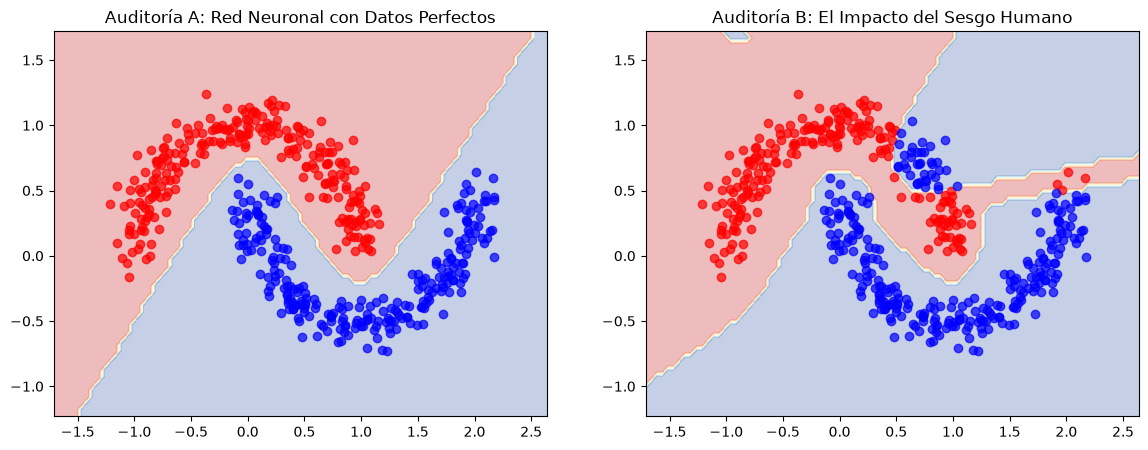

In [2]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

# 1. Generamos el dataset perfecto y el saboteado
X_moons, y_moons = make_moons(n_samples=500, noise=0.1, random_state=42)
Y_perfecto = y_moons.reshape(-1, 1)

Y_corrupto = np.copy(Y_perfecto)
# Simulamos el error humano: Invertimos las etiquetas en el sector superior derecho
sector_saboteado = (X_moons[:, 0] > 0.5) & (X_moons[:, 1] > 0.5)
Y_corrupto[sector_saboteado] = 1 - Y_corrupto[sector_saboteado]

# 2. Función auxiliar para entrenar la red
def entrenar_auditoria(X, Y, arquitectura, epochs=10000):
    # Instanciamos tu clase dinámica
    modelo = RedNeuronalProfunda(arquitectura, learning_rate=1.2)
    for i in range(epochs):
        A_final, cache = modelo.forward_propagation(X)
        gradientes = modelo.backward_propagation(X, Y, cache)
        modelo.update_parameters(gradientes)
    return modelo

# 3. Entrenamos ambas redes en paralelo
arquitectura_elegida = [2, 10, 10, 1]
print("Entrenando Modelo 1: Datos Curados...")
red_perfecta = entrenar_auditoria(X_moons, Y_perfecto, arquitectura_elegida)

print("Entrenando Modelo 2: Datos Saboteados (Error Humano)...")
red_corrupta = entrenar_auditoria(X_moons, Y_corrupto, arquitectura_elegida)

# 4. Visualización del impacto (La demostración de Auditoría)
# Creamos la malla topológica para dibujar la frontera de decisión
x_min, x_max = X_moons[:,0].min() - 0.5, X_moons[:,0].max() + 0.5
y_min, y_max = X_moons[:,1].min() - 0.5, X_moons[:,1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

# Pasamos la malla por las redes ya entrenadas
A_perf, _ = red_perfecta.forward_propagation(np.c_[xx.ravel(), yy.ravel()])
A_corr, _ = red_corrupta.forward_propagation(np.c_[xx.ravel(), yy.ravel()])

Z_perf = (A_perf > 0.5).astype(int).reshape(xx.shape)
Z_corr = (A_corr > 0.5).astype(int).reshape(xx.shape)

# Graficamos los resultados finales
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: El Modelo Ideal
ax[0].contourf(xx, yy, Z_perf, alpha=0.3, cmap=plt.cm.RdYlBu)
ax[0].scatter(X_moons[y_moons==0, 0], X_moons[y_moons==0, 1], color='red', alpha=0.7)
ax[0].scatter(X_moons[y_moons==1, 0], X_moons[y_moons==1, 1], color='blue', alpha=0.7)
ax[0].set_title("Auditoría A: Red Neuronal con Datos Perfectos")

# Gráfico 2: El Modelo Saboteado
ax[1].contourf(xx, yy, Z_corr, alpha=0.3, cmap=plt.cm.RdYlBu)
ax[1].scatter(X_moons[Y_corrupto.flatten()==0, 0], X_moons[Y_corrupto.flatten()==0, 1], color='red', alpha=0.7)
ax[1].scatter(X_moons[Y_corrupto.flatten()==1, 0], X_moons[Y_corrupto.flatten()==1, 1], color='blue', alpha=0.7)
ax[1].set_title("Auditoría B: El Impacto del Sesgo Humano")

plt.show()

3. **Conclusión y Valor Profesional**

 *Este experimento demuestra visualmente un principio fundamental de la Inteligencia Artificial:* 
 un algoritmo matemáticamente perfecto colapsa si la curaduría de sus datos es deficiente.Comprender la arquitectura interna de un modelo de Machine Learning me permite abordar tareas de anotación de datos y entrenamiento de IA no como un proceso mecánico, sino con una visión analítica integral. Conozco exactamente cómo un falso positivo, un sesgo de selección o un error de etiquetado en la etapa de preprocesamiento se propaga a través de los gradientes matemáticos, destruyendo la precisión final del modelo en producción.